# Binary Gravitational-Wave Signal Detection Dataset (H1 + L1)

This notebook builds a binary-classification dataset for **BBH gravitational-wave signal detection** with the **two LIGO detectors (H1 and L1) treated as one network**, following the recipe of Choudhary et al., *Phys. Rev. D* **107**, 024030 wherever the paper is specific:

- `y = 0`: real LIGO noise only (H1 and L1 windows from the same GPS time)
- `y = 1`: the same kind of real noise with **one simulated binary-black-hole (BBH) event injected coherently into both detectors**
- BBH waveforms are generated with **PyCBC** (`IMRPhenomPv2`, non-spinning, m1, m2 ~ U[10, 100] Msun, isotropic sky/orientation)
- the *same* masses, sky position, polarisation and inclination are used for H1 and L1; each detector gets its own antenna pattern (`F+`, `Fx`), and the L1 signal is shifted by the **light-travel-time delay** between the sites
- the amplitude is set so that the **optimal matched-filter SNR in H1** is ~ U[4, 10] (as in the paper); the L1 SNR follows from the sky position and the L1 PSD
- real detector strain is obtained from **GWOSC** (one H1 file and one L1 file covering the same GPS span)
- every file pair is split **in time** into a train part and a test part *before* any example is made, so train and test never share noise
- every example is a **2 s window**, tapered, whitened with the PSD of its own detector and noise stretch, and band-limited to 20–1000 Hz; the H1 merger sits at the centre of the window

The output is `X.shape = (n_examples, 2, 8192)`, where channel 0 is H1 and channel 1 is L1. It can be used directly as a 2-channel 1-D input, or turned into time-frequency maps (such as the SGP maps of the paper, which are **not** part of this notebook).

Glitch (blip) examples are also **not** part of this notebook.

## 1. Installation

Run this cell once in the environment where you want to build the dataset.

If you are using Conda, create an environment first:

```bash
conda create -n gwml python=3.11
conda activate gwml
```

Then install the required packages:

```bash
pip install pycbc gwosc h5py scipy numpy pandas matplotlib scikit-learn
```


In [1]:
# If the packages are already installed, you can skip this cell.
# Run from a notebook only if your Jupyter kernel is using the desired environment.

%pip install pycbc gwosc h5py scipy numpy pandas matplotlib scikit-learn


Note: you may need to restart the kernel to use updated packages.


## 2. Imports and configuration

In [2]:
import os
import h5py
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from functools import lru_cache

from scipy.signal import butter, sosfiltfilt, welch
from scipy.signal.windows import tukey

from pycbc.detector import Detector
from pycbc.waveform import get_td_waveform

SEED = 42
rng = np.random.default_rng(SEED)

# ------------------------------------------------------------------
# Dataset configuration (values follow the paper where it gives them)
# ------------------------------------------------------------------
FS = 4096                      # sampling frequency [Hz]
WINDOW_DURATION = 2.0          # duration of each example [s] (paper: 2 s)
N_SAMPLES = int(round(FS * WINDOW_DURATION))

DETECTORS = ("H1", "L1")        # channel order of X; the FIRST one is the SNR reference detector
INJECTION_PAD = 512            # samples of zero padding used while time-shifting a waveform (> max 10 ms delay)

F_LOW = 20.0                   # lower edge of the analysis band [Hz]
F_HIGH = 1000.0                # upper edge of the analysis band [Hz]
HP_CORNER = 15.0               # zero-phase high-pass applied to the long noise stretch [Hz]
EDGE_TRIM = 2.0                # seconds discarded at both ends of a file (filter transients)

APPROXIMANT = "IMRPhenomPv2"   # paper: IMRPhenomPv2, non-spinning
MASS_RANGE = (10.0, 100.0)     # component masses ~ U[10, 100] Msun (m1 >= m2 enforced)
SNR_RANGE = (4.0, 10.0)        # target optimal matched-filter SNR in the reference detector (H1)
REF_DISTANCE = 1000.0          # Mpc, distance at which waveforms are generated before SNR scaling

TRAIN_FRACTION = 0.8           # first 80 % of every file -> train, last 20 % -> test
TUKEY_ALPHA = 0.2              # taper applied to every 2 s window
PSD_SEG_DURATION = 4.0         # Welch segment length [s]

N_TRAIN = 8000
N_TEST = 2000

RAW_DIR = "raw_noise"
DATASET_DIR = "gw_bbh_dataset"

os.makedirs(RAW_DIR, exist_ok=True)
os.makedirs(DATASET_DIR, exist_ok=True)

WINDOW = tukey(N_SAMPLES, alpha=TUKEY_ALPHA)

print("Samples per example:", N_SAMPLES)

/usr/lib/python3.12/importlib/__init__.py:90: UserWarning: Wswiglal-redir-stdio:

SWIGLAL standard output/error redirection is enabled in IPython.
This may lead to performance penalties. To disable locally, use:

with lal.no_swig_redirect_standard_output_error():
    ...

To disable globally, use:

lal.swig_redirect_standard_output_error(False)

Note however that this will likely lead to error messages from
LAL functions being either misdirected or lost when called from
Jupyter notebooks.

To suppress this warning, use:

import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")
import lal

  return _bootstrap._gcd_import(name[level:], package, level)


Samples per example: 8192


## 3. Read GWOSC HDF5 strain

In [3]:
def read_gwosc_hdf5(filename):
    """Read strain and basic metadata from a GWOSC HDF5 file.

    Returns
    -------
    strain : float64 ndarray
    gps_start : float, GPS time of the first sample
    sample_rate : float
    detector : str or None ("H1", "L1", ... as stored in the file)
    """

    with h5py.File(filename, "r") as f:
        strain = np.asarray(f["strain/Strain"][:], dtype=np.float64)

        gps_start = float(f["meta/GPSstart"][()])
        duration = float(f["meta/Duration"][()])

        detector = None
        if "meta/Detector" in f:
            detector = f["meta/Detector"][()]
            if isinstance(detector, bytes):
                detector = detector.decode()
            detector = str(detector)

    sample_rate = len(strain) / duration

    return strain, gps_start, sample_rate, detector

## 4. Noise conditioning, PSD estimation and whitening

The long noise stretch is **high-passed once** (zero-phase) so that the huge seismic/low-frequency power cannot leak into the band through the window taper. Its PSD is then estimated with Welch's method (median average, robust to short glitches).

An example is made by tapering a raw 2 s crop, adding the injection (if any), and whitening **the sum**:

```text
X = irfft( rfft(window * (noise + signal)) / sqrt(PSD) ),   keeping only 20-1000 Hz
```

Bins outside the analysis band are set to zero **after** whitening instead of dividing by the (tiny) PSD there, so nothing outside the band can be amplified. The output is scaled so that stationary noise has unit variance.

`optimal_snr` uses exactly the same PSD, band and FFT conventions, so the SNR written to the metadata is the SNR the whitened data really contains.

In [4]:
def highpass(strain, fs, corner=HP_CORNER, order=4):
    """Zero-phase Butterworth high-pass.

    Non-finite samples (gaps) are zeroed before filtering, because a single NaN
    would contaminate the whole IIR output, and are set back to NaN afterwards
    (padded by 1 s) so that any window overlapping a gap is rejected later.
    """

    bad = ~np.isfinite(strain)
    x = np.where(bad, 0.0, strain) if bad.any() else strain

    sos = butter(order, corner, btype="highpass", fs=fs, output="sos")
    y = sosfiltfilt(sos, x)

    if bad.any():
        pad = int(fs)
        idx = np.flatnonzero(bad)
        run_start = idx[np.r_[True, np.diff(idx) > 1]]
        run_end = idx[np.r_[np.diff(idx) > 1, True]]
        for s, e in zip(run_start, run_end):
            y[max(0, s - pad): e + pad + 1] = np.nan

    return y


def estimate_psd(strain, fs, seg_duration=PSD_SEG_DURATION):
    """One-sided strain PSD [1/Hz] from a long stretch (Welch, median average).

    Returns (frequencies, psd).
    """

    strain = strain[np.isfinite(strain)]
    nperseg = int(seg_duration * fs)

    if len(strain) < 4 * nperseg:
        raise ValueError("Noise stretch too short for a reliable PSD estimate.")

    freqs, pxx = welch(
        strain,
        fs=fs,
        nperseg=nperseg,
        noverlap=nperseg // 2,
        window="hann",
        average="median",
    )

    return freqs, pxx


def band_mask(n, fs, f_low=F_LOW, f_high=F_HIGH):
    """rfft frequencies and a boolean mask of the analysis band."""

    freqs = np.fft.rfftfreq(n, 1.0 / fs)
    return freqs, (freqs >= f_low) & (freqs <= f_high)


def psd_on_band(psd, n, fs):
    """Interpolate a (freqs, pxx) PSD onto the rfft grid of an n-sample example."""

    freqs, band = band_mask(n, fs)
    f_psd, pxx = psd
    S = np.interp(freqs, f_psd, pxx)

    if not np.all(S[band] > 0):
        raise ValueError("PSD is zero or negative inside the analysis band.")

    return freqs, band, S


def whiten(x, psd, fs):
    """Whiten an (already tapered) strain segment and keep only F_LOW-F_HIGH.

    The output is normalised so that stationary Gaussian noise with the given
    PSD has unit variance (where the window equals 1).
    """

    n = len(x)
    dt = 1.0 / fs

    _, band, S = psd_on_band(psd, n, fs)

    X = np.fft.rfft(x) * dt
    Xw = np.zeros_like(X)
    Xw[band] = X[band] / np.sqrt(S[band])

    y = np.fft.irfft(Xw, n=n)

    return y * np.sqrt(n / (band.sum() * dt))


def optimal_snr(h, psd, fs):
    """Optimal matched-filter SNR of a waveform h (already windowed):

        rho^2 = 4 * integral_{F_LOW}^{F_HIGH} |h(f)|^2 / S(f) df
    """

    n = len(h)
    dt = 1.0 / fs

    _, band, S = psd_on_band(psd, n, fs)

    H = np.fft.rfft(h) * dt
    df = 1.0 / (n * dt)

    return float(np.sqrt(4.0 * df * np.sum(np.abs(H[band]) ** 2 / S[band])))


def snr_from_whitened(y, fs=FS):
    """Optimal SNR recovered from a whitened, band-limited, unit-variance signal.

    Used only as an independent check of the normalisation of `whiten`.
    """

    n = len(y)
    _, band = band_mask(n, fs)

    return float(np.sqrt(np.sum(y ** 2) * 2.0 * band.sum() / n))

## 5. Draw random noise windows

Instead of cutting the file into fixed, non-overlapping blocks and re-using them with replacement (which silently duplicated noise-only examples), each example gets its **own random 2 s crop** from a noise *stream*. A stream is one contiguous GPS span, holding the strain and PSD of **both** detectors. The same time span is cropped from H1 and L1, and a window is rejected if either detector has a data gap (NaN) in it.

In [5]:
def sample_noise_window(streams, rng, n=N_SAMPLES, max_tries=100):
    """Return ({detector: raw_noise_window}, stream, start_sample) for a random crop.

    The SAME time span is cropped from every detector. Streams are chosen in
    proportion to how many windows they can supply.
    """

    ref = DETECTORS[0]
    weights = np.array([len(s["strain"][ref]) - n + 1 for s in streams], dtype=float)

    if np.any(weights <= 0):
        raise ValueError("A noise stream is shorter than one example window.")

    weights /= weights.sum()

    for _ in range(max_tries):
        stream = streams[rng.choice(len(streams), p=weights)]
        start = int(rng.integers(0, len(stream["strain"][ref]) - n + 1))

        crops = {d: stream["strain"][d][start:start + n] for d in DETECTORS}

        if all(np.all(np.isfinite(c)) for c in crops.values()):
            return {d: c.copy() for d, c in crops.items()}, stream, start

    raise RuntimeError("Could not find a gap-free noise window (too many NaNs?).")

## 6. Generate BBH waveforms

PyCBC's time-domain generator is used with the paper's settings:

- `IMRPhenomPv2` (non-spinning), lower frequency 20 Hz
- component masses uniform in [10, 100] Msun (the heavier one is called `mass1`)
- sky position isotropic (`ra` uniform, `sin(dec)` uniform), polarisation uniform, `cos(inclination)` uniform
- waveforms are generated once at a fixed reference distance and **projected onto each detector** with that detector's antenna pattern (`h = F+ h+ + Fx hx`)
- the signal in L1 is **delayed by the arrival-time difference** `t(L1) - t(H1)` for that sky position (up to about +-10 ms), applied as a fractional-sample phase shift
- the merger (`t = 0` of the PyCBC waveform) is placed at the **centre** of the 2 s window in H1

In [6]:
def generate_bbh(
    mass1,
    mass2,
    distance=REF_DISTANCE,
    inclination=0.0,
    delta_t=1.0 / FS,
    approximant=APPROXIMANT,
):
    """Generate the plus/cross polarizations of a BBH waveform (PyCBC TimeSeries).

    The time axis is such that t = 0 is the merger.
    """

    hp, hc = get_td_waveform(
        approximant=approximant,
        mass1=mass1,
        mass2=mass2,
        distance=distance,
        inclination=inclination,
        delta_t=delta_t,
        f_lower=F_LOW,
    )

    return hp, hc


@lru_cache(maxsize=None)
def get_detector(name):
    return Detector(name)


def project_to_detector(hp, hc, detector_name, ra, dec, polarization, gps_time):
    """Detector response h = F+ h+ + Fx hx for a given sky position."""

    fplus, fcross = get_detector(detector_name).antenna_pattern(
        ra, dec, polarization, gps_time
    )
    fplus, fcross = float(fplus), float(fcross)

    h = fplus * np.asarray(hp) + fcross * np.asarray(hc)

    return h, fplus, fcross


def detector_delay(detector_name, reference_name, ra, dec, gps_time):
    """Arrival-time difference t(detector) - t(reference) in seconds.

    Positive means the signal reaches `detector` AFTER `reference`.
    """

    return float(
        get_detector(detector_name).time_delay_from_detector(
            get_detector(reference_name), ra, dec, gps_time
        )
    )


def shift_waveform(x, delay, fs):
    """Delay x by `delay` seconds (fractional samples allowed): x(t) -> x(t - delay).

    Done with a Fourier-domain phase shift, which is circular, so x must be
    zero-padded at both ends by more than |delay| (see INJECTION_PAD).
    """

    freqs = np.fft.rfftfreq(len(x), 1.0 / fs)

    return np.fft.irfft(
        np.fft.rfft(x) * np.exp(-2j * np.pi * freqs * delay),
        n=len(x),
    )

Waveform samples: 65536
Waveform length [s]: 16.0 | merger (t=0) at sample 45056


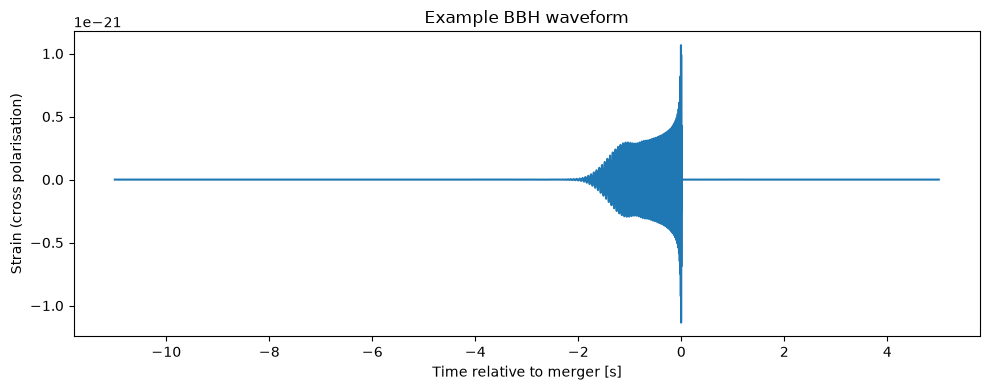

In [7]:
# Test one waveform

hp, hc = generate_bbh(
    mass1=30,
    mass2=20,
    distance=500
)

print("Waveform samples:", len(hc))
print("Waveform length [s]:", len(hc) / FS, "| merger (t=0) at sample", int(round(-float(hp.start_time) * FS)))

plt.figure(figsize=(10, 4))
plt.plot(np.asarray(hc.sample_times), np.asarray(hc))
plt.xlabel("Time relative to merger [s]")
plt.ylabel("Strain (cross polarisation)")
plt.title("Example BBH waveform")
plt.tight_layout()
plt.show()

## 7. Scale the waveform to a target matched-filter SNR

The waveform is scaled so that its **optimal matched-filter SNR in the reference detector (H1)** equals the target value, using the PSD of the H1 noise it will be injected into:

```text
rho_opt^2 = 4 * integral |h(f)|^2 / S(f) df      (20-1000 Hz)
```

The same amplitude scale is applied to the L1 signal, so the **L1 SNR is not drawn but follows** from the sky position (antenna pattern) and the L1 PSD, exactly like in the paper. Because the amplitude is set by the SNR, the *effective distance* that corresponds to it is stored in the metadata as `distance`.

In [8]:
def scale_to_snr(waveform, psd, fs, target_snr):
    """Scale a (windowed) detector-frame waveform to a target optimal SNR.

    Returns (scaled_waveform, scale). Amplitude is proportional to 1/distance,
    so the distance that gives the target SNR is REF_DISTANCE / scale.
    """

    rho = optimal_snr(waveform, psd, fs)

    if not np.isfinite(rho) or rho <= 0:
        raise ValueError("Waveform has zero SNR in the analysis band.")

    scale = target_snr / rho

    return waveform * scale, scale

## 8. Inject a waveform into detector noise

In [9]:
def place_waveform(h, merger_index, n=N_SAMPLES):
    """Return a length-n array with h shifted so that sample `merger_index`
    of h (the merger) lands on the centre sample n // 2.

    Parts of h that fall outside the window are cut off (for light systems the
    early inspiral is much longer than the window); missing parts are zero.
    """

    out = np.zeros(n)

    offset = n // 2 - merger_index          # position of h[0] inside the window
    src_start = max(0, -offset)
    dst_start = max(0, offset)
    length = min(len(h) - src_start, n - dst_start)

    if length > 0:
        out[dst_start:dst_start + length] = h[src_start:src_start + length]

    return out

## 9. Create positive and negative examples

Both classes go through **exactly the same processing** (taper -> add injection -> whiten each detector with its own PSD); the only difference is whether an injection is added. The injection is windowed with the same taper as the noise, so the whitened example equals `whiten(window * noise + window * h)` in each detector.

In [10]:
def example_meta(stream, start, fs=FS, n=N_SAMPLES):
    """Metadata shared by both classes."""

    return {
        "gps_time": stream["gps_start"] + (start + n / 2) / fs,   # centre of the window
    }


def empty_injection_meta():
    """Metadata of a noise-only example (same columns as an injection)."""

    ref = DETECTORS[0]

    meta = {
        "mass1": np.nan,
        "mass2": np.nan,
        "distance": np.nan,
        "injection_index": -1,
        "ra": np.nan,
        "dec": np.nan,
        "polarization": np.nan,
        "inclination": np.nan,
        "snr_network": 0.0,
    }

    for d in DETECTORS:
        meta[f"snr_{d}"] = 0.0
        meta[f"f_plus_{d}"] = np.nan
        meta[f"f_cross_{d}"] = np.nan
        if d != ref:
            meta[f"delay_{d}_{ref}"] = np.nan

    return meta


def make_injection(stream, start, rng, fs=FS, window=WINDOW, n=N_SAMPLES):
    """Draw ONE set of BBH parameters and build the scaled, windowed
    detector-frame waveform of every detector (length n each, H1 merger at the
    centre, other detectors delayed by the light-travel time).

    Returns ({detector: h}, meta).
    """

    ref = DETECTORS[0]
    psd = stream["psd"]
    gps_center = stream["gps_start"] + (start + n / 2) / fs

    n_pad = n + 2 * INJECTION_PAD

    for _ in range(20):
        # Masses: m1 >= m2, both ~ U[10, 100] Msun.
        m2, m1 = np.sort(rng.uniform(*MASS_RANGE, size=2))

        # Isotropic sky position, polarisation and inclination.
        ra = rng.uniform(0.0, 2.0 * np.pi)
        dec = np.arcsin(rng.uniform(-1.0, 1.0))
        pol = rng.uniform(0.0, 2.0 * np.pi)
        inc = np.arccos(rng.uniform(-1.0, 1.0))

        target_snr = rng.uniform(*SNR_RANGE)      # in the reference detector

        hp, hc = generate_bbh(
            float(m1), float(m2),
            distance=REF_DISTANCE,
            inclination=float(inc),
            delta_t=1.0 / fs,
        )

        merger_index = int(round(-float(hp.start_time) * fs))

        h = {}
        fplus = {}
        fcross = {}
        delay = {}

        for d in DETECTORS:
            hd, fplus[d], fcross[d] = project_to_detector(
                hp, hc, d, ra, dec, pol, gps_center
            )

            # Merger of the reference detector at the centre of a padded window ...
            hd = place_waveform(hd, merger_index, n_pad)

            # ... other detectors see it later/earlier by the light-travel time.
            delay[d] = 0.0 if d == ref else detector_delay(d, ref, ra, dec, gps_center)
            if delay[d] != 0.0:
                hd = shift_waveform(hd, delay[d], fs)

            # Crop the padding away and apply the SAME taper as the noise.
            h[d] = hd[INJECTION_PAD:INJECTION_PAD + n] * window

        # Amplitude from the SNR in the reference detector; same scale for all.
        try:
            _, scale = scale_to_snr(h[ref], psd[ref], fs, target_snr)
        except ValueError:
            continue

        h = {d: h[d] * scale for d in DETECTORS}

        meta = {
            "mass1": float(m1),
            "mass2": float(m2),
            "distance": REF_DISTANCE / scale,     # effective distance [Mpc] for this SNR
            "injection_index": n // 2,            # merger sample in the reference detector
            "ra": float(ra),
            "dec": float(dec),
            "polarization": float(pol),
            "inclination": float(inc),
        }

        snrs = {d: optimal_snr(h[d], psd[d], fs) for d in DETECTORS}

        meta["snr_network"] = float(np.sqrt(sum(s ** 2 for s in snrs.values())))

        for d in DETECTORS:
            meta[f"snr_{d}"] = snrs[d]
            meta[f"f_plus_{d}"] = fplus[d]
            meta[f"f_cross_{d}"] = fcross[d]
            if d != ref:
                meta[f"delay_{d}_{ref}"] = delay[d]

        return h, meta

    raise RuntimeError("Could not generate a waveform with non-zero SNR.")


def create_noise_example(noise, stream, start, rng, fs=FS, window=WINDOW):
    """
    Class 0: real detector noise only (all detectors, same GPS time).

    Every raw noise window is tapered and whitened with the PSD of its own
    detector and noise stream. Returns an array of shape (n_detectors, n).
    """

    whitened = np.stack([
        whiten(noise[d] * window, stream["psd"][d], fs)
        for d in DETECTORS
    ])

    meta = empty_injection_meta()
    meta.update(example_meta(stream, start, fs, len(noise[DETECTORS[0]])))

    return whitened, meta


def create_signal_example(noise, stream, start, rng, fs=FS, window=WINDOW):
    """
    Class 1: real detector noise + one coherent simulated BBH signal.

    The BBH waveform is projected on each detector, scaled to the target SNR
    (set in H1), delayed for L1, and added to the tapered raw noise of that
    detector. The complete noise + signal segments are then whitened.
    """

    n = len(noise[DETECTORS[0]])

    h, meta = make_injection(stream, start, rng, fs, window, n)

    whitened = np.stack([
        whiten(noise[d] * window + h[d], stream["psd"][d], fs)
        for d in DETECTORS
    ])

    meta.update(example_meta(stream, start, fs, n))

    return whitened, meta

## 10. Build the dataset

In [11]:
def make_dataset(
    streams,
    n_examples=1000,
    fs=FS,
    balanced=True,
    rng=rng,
    progress_every=500,
):
    """Generate a binary BBH-vs-noise dataset from a list of noise streams.

    Returns X with shape (n_examples, n_detectors, N_SAMPLES) in the order of
    DETECTORS, y with shape (n_examples,) and a metadata DataFrame.
    """

    if len(streams) == 0:
        raise ValueError("No noise streams supplied.")

    X = []
    y = []
    metadata = []

    if balanced:

        n_signal = n_examples // 2
        n_noise = n_examples - n_signal

        labels = np.array(
            [0] * n_noise +
            [1] * n_signal
        )

        rng.shuffle(labels)

    else:

        labels = rng.integers(0, 2, size=n_examples)

    for i, label in enumerate(labels):

        # Pick a random raw noise window (same time span in every detector).
        noise, stream, start = sample_noise_window(streams, rng, N_SAMPLES)

        if label == 0:
            example, meta = create_noise_example(noise, stream, start, rng, fs=fs)
        else:
            example, meta = create_signal_example(noise, stream, start, rng, fs=fs)

        X.append(example)
        y.append(label)
        metadata.append(meta)

        if (i + 1) % progress_every == 0:
            print(f"{i + 1}/{n_examples}")

    return (
        np.asarray(X, dtype=np.float32),
        np.asarray(y, dtype=np.int64),
        pd.DataFrame(metadata)
    )

## 11. Prepare real noise

This section assumes you have downloaded GWOSC HDF5 files into `raw_noise/`: **for every GPS span one file for H1 and one for L1** (e.g. `H-H1_GWOSC_O4b_4KHZ_R1-1396420608-4096.hdf5` and `L-L1_GWOSC_O4b_4KHZ_R1-1396420608-4096.hdf5`).

For each file:

1. read the strain (and the detector name),
2. high-pass the long stretch and drop `EDGE_TRIM` seconds at both ends,

then the H1 and L1 files with the same GPS start are paired and, for each pair,

3. **split in time**: the first `TRAIN_FRACTION` is the train stream, the rest is the test stream (same split point for both detectors),
4. estimate a PSD for every detector and every part separately (no test data is used to whiten train data, or the other way round).

Several GPS spans can be put in `raw_noise/`; each contributes a train and a test stream. A file without a partner for the other detector (same GPS start and length) raises an error.

In [12]:
def load_noise_streams(filenames, fs=FS, train_fraction=TRAIN_FRACTION):
    """
    Load real GWOSC strain files, high-pass them, pair the files of all
    detectors that cover the same GPS span, split every pair in time into a
    train part and a test part, and estimate a PSD for every detector and part.

    Returns
    -------
    train_streams, test_streams : lists of dicts with keys
        name, gps_start (GPS time of the first sample), fs,
        strain = {detector: ndarray}, psd = {detector: (freqs, psd)}
    """

    trim = int(EDGE_TRIM * fs)
    spans = {}          # original GPS start -> {detector: (strain, filename)}

    for filename in filenames:

        strain, gps_start, file_fs, detector = read_gwosc_hdf5(filename)

        print(
            os.path.basename(filename),
            "| GPS =", int(gps_start),
            "| file fs =", file_fs,
            "| detector =", detector,
        )

        if not np.isclose(file_fs, fs):
            raise ValueError(
                f"{filename}: expected fs={fs}, found fs={file_fs}"
            )

        # GWOSC files are named like H-H1_GWOSC_..., use that if the file has no metadata.
        if detector is None:
            detector = os.path.basename(filename).split("-")[1].split("_")[0]

        if detector not in DETECTORS:
            raise ValueError(f"{filename}: unsupported detector '{detector}'")

        # High-pass the LONG stretch first, then drop the filter edges.
        strain = highpass(strain, fs)
        strain = strain[trim:len(strain) - trim]

        per_detector = spans.setdefault(int(round(gps_start)), {})

        if detector in per_detector:
            raise ValueError(
                f"Two {detector} files start at GPS {int(gps_start)}."
            )

        per_detector[detector] = (strain, filename)

    train_streams = []
    test_streams = []

    for gps_start, per_detector in sorted(spans.items()):

        missing = [d for d in DETECTORS if d not in per_detector]
        if missing:
            raise ValueError(
                f"GPS span {gps_start}: no file for {missing}. "
                f"Every span needs one file per detector {DETECTORS}."
            )

        lengths = {len(per_detector[d][0]) for d in DETECTORS}
        if len(lengths) != 1:
            raise ValueError(
                f"GPS span {gps_start}: the detector files have different lengths."
            )

        n_total = lengths.pop()
        first_sample_gps = gps_start + trim / fs

        # Split in TIME so that train and test never share noise.
        split = int(train_fraction * n_total)

        parts = (
            ("train", 0, split, train_streams),
            ("test", split, n_total, test_streams),
        )

        for tag, lo, hi, bucket in parts:

            segment = {d: per_detector[d][0][lo:hi] for d in DETECTORS}

            bucket.append({
                "name": f"{gps_start}[{tag}]",
                "gps_start": first_sample_gps + lo / fs,
                "fs": fs,
                "strain": segment,
                "psd": {d: estimate_psd(segment[d], fs) for d in DETECTORS},
            })

    if len(train_streams) == 0:
        raise ValueError("No noise files supplied.")

    return train_streams, test_streams

In [13]:
# Find downloaded HDF5 files.

noise_files = sorted(
    os.path.join(RAW_DIR, f)
    for f in os.listdir(RAW_DIR)
    if f.endswith((".hdf5", ".h5"))
)

print("Found:", len(noise_files), "HDF5 files")

if len(noise_files) == 0:
    raise FileNotFoundError(
        f"Put one GWOSC strain file (.hdf5) per detector {DETECTORS} "
        f"and GPS span into '{RAW_DIR}/' first."
    )

train_streams, test_streams = load_noise_streams(noise_files)

for tag, streams in (("train", train_streams), ("test", test_streams)):
    for s in streams:
        n_seconds = len(s["strain"][DETECTORS[0]]) / FS
        print(
            f"{tag:5s} {'+'.join(DETECTORS)}  {n_seconds:8.0f} s  "
            f"GPS {s['gps_start']:.0f} -> {s['gps_start'] + n_seconds:.0f}"
        )

Found: 2 HDF5 files
H-H1_GWOSC_O4b_4KHZ_R1-1396420608-4096.hdf5 | GPS = 1396420608 | file fs = 4096.0 | detector = H1
L-L1_GWOSC_O4b_4KHZ_R1-1396420608-4096.hdf5 | GPS = 1396420608 | file fs = 4096.0 | detector = L1
train H1+L1      3274 s  GPS 1396420610 -> 1396423884
test  H1+L1       818 s  GPS 1396423884 -> 1396424702


## 12. Train/test split (done in time, before generating examples) and pre-flight check

The split already happened in `load_noise_streams`:

```text
real detector data (one H1 + L1 file pair)
       |
       +---- first 80 %  (train stream, own PSDs) ---> generate train examples
       |
       +---- last  20 %  (test  stream, own PSDs) ---> generate test examples
```

A random split of short blocks puts neighbouring (strongly correlated) noise into both sets; a split in time does not.

Before generating the full dataset, the next cell runs two quick checks:

1. **noise normalisation** (per detector): whitened noise-only windows should have a standard deviation close to 1 (a warning is printed otherwise; real data can be a bit off because of non-stationarity or glitches),
2. **SNR consistency** (hard assertion): for every detector, the SNR that the whitened injection actually contains must equal the SNR written to the metadata, and the H1 SNR must lie in `SNR_RANGE`.

In [15]:
def preflight_checks(streams, n_noise=100, n_signal=10, seed=123):
    r = np.random.default_rng(seed)

    # 1) Noise normalisation per detector (central second, where the taper is 1).
    stds = {d: [] for d in DETECTORS}
    for _ in range(n_noise):
        noise, stream, start = sample_noise_window(streams, r)
        for d in DETECTORS:
            x = whiten(noise[d] * WINDOW, stream["psd"][d], FS)
            stds[d].append(np.std(x[N_SAMPLES // 4: 3 * N_SAMPLES // 4]))

    for d in DETECTORS:
        s = np.array(stds[d])
        print(f"{d} whitened noise std: mean={s.mean():.3f}  min={s.min():.3f}  max={s.max():.3f}  (expect ~1)")

        if not (0.8 < s.mean() < 1.25):
            print(f"WARNING: whitened {d} noise is not close to unit variance - check the data/PSD.")

    # 2) The SNR contained in each whitened injection must equal the SNR in the metadata.
    for _ in range(n_signal):
        noise, stream, start = sample_noise_window(streams, r)
        h, meta = make_injection(stream, start, r)

        for d in DETECTORS:
            rho = snr_from_whitened(whiten(h[d], stream["psd"][d], FS))
            assert np.isclose(rho, meta[f"snr_{d}"], rtol=1e-6, atol=1e-9), (d, rho, meta[f"snr_{d}"])

        assert SNR_RANGE[0] - 1e-6 <= meta[f"snr_{DETECTORS[0]}"] <= SNR_RANGE[1] + 1e-6

    print(f"SNR consistency check passed on {n_signal} injections (all detectors).")


preflight_checks(train_streams)
preflight_checks(test_streams)

H1 whitened noise std: mean=1.051  min=0.993  max=1.113  (expect ~1)
L1 whitened noise std: mean=1.013  min=0.961  max=1.073  (expect ~1)
SNR consistency check passed on 10 injections (all detectors).
H1 whitened noise std: mean=1.050  min=1.000  max=1.106  (expect ~1)
L1 whitened noise std: mean=1.019  min=0.969  max=1.086  (expect ~1)
SNR consistency check passed on 10 injections (all detectors).


## 13. Generate train and test datasets

In [16]:
# Generate the training dataset (from the TRAIN noise streams only).

X_train, y_train, meta_train = make_dataset(
    train_streams,
    n_examples=N_TRAIN
)

# Generate the test dataset (from the TEST noise streams only).

X_test, y_test, meta_test = make_dataset(
    test_streams,
    n_examples=N_TEST
)

print("Train:", X_train.shape, y_train.shape)
print("Test: ", X_test.shape, y_test.shape)

500/8000
1000/8000
1500/8000
2000/8000
2500/8000
3000/8000
3500/8000
4000/8000
4500/8000
5000/8000
5500/8000
6000/8000
6500/8000
7000/8000
7500/8000
8000/8000
500/2000
1000/2000
1500/2000
2000/2000
Train: (8000, 2, 8192) (8000,)
Test:  (2000, 2, 8192) (2000,)


## 14. Save the dataset

In [17]:
def save_dataset(X, y, metadata, split):
    split_dir = os.path.join(DATASET_DIR, split)
    os.makedirs(split_dir, exist_ok=True)

    np.save(os.path.join(split_dir, "X.npy"), X)
    np.save(os.path.join(split_dir, "y.npy"), y)
    metadata.to_csv(
        os.path.join(split_dir, "metadata.csv"),
        index=False
    )

    print("Saved", split, "dataset to", split_dir)


save_dataset(X_train, y_train, meta_train, "train")
save_dataset(X_test, y_test, meta_test, "test")

Saved train dataset to gw_bbh_dataset/train
Saved test dataset to gw_bbh_dataset/test


## 15. Inspect examples

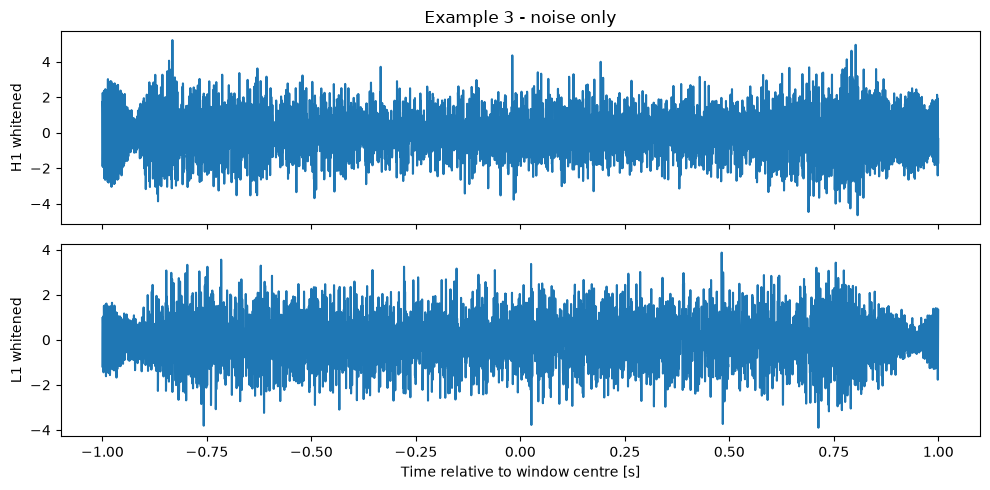

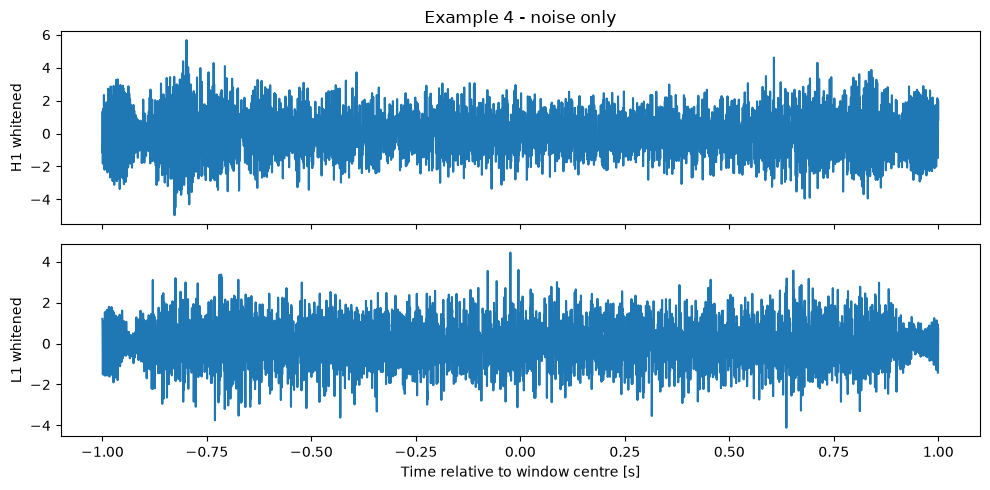

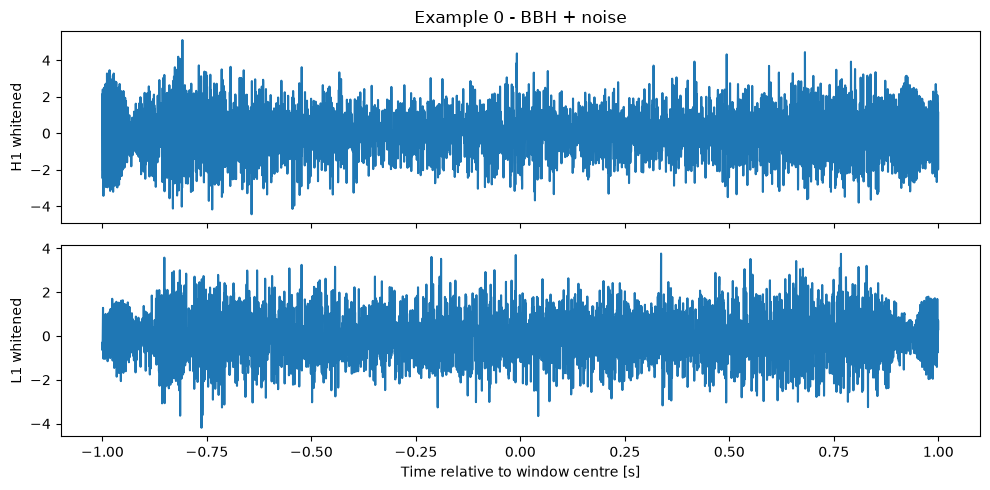

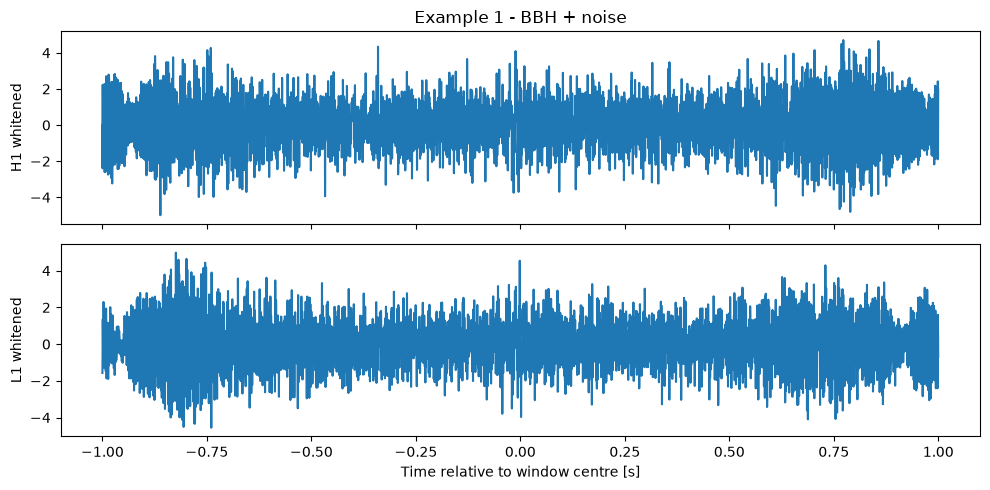

In [18]:
def plot_examples(X, y, n_per_class=2, fs=FS):
    """Plot a few noise-only and signal+noise examples (H1 merger at t = 0)."""

    t = (np.arange(X.shape[-1]) - X.shape[-1] // 2) / fs

    for label, name in ((0, "noise only"), (1, "BBH + noise")):
        for idx in np.flatnonzero(y == label)[:n_per_class]:
            fig, axes = plt.subplots(
                len(DETECTORS), 1, figsize=(10, 2.5 * len(DETECTORS)), sharex=True
            )

            for ax, d, series in zip(np.atleast_1d(axes), DETECTORS, X[idx]):
                ax.plot(t, series)
                ax.set_ylabel(f"{d} whitened")

            np.atleast_1d(axes)[-1].set_xlabel("Time relative to window centre [s]")
            np.atleast_1d(axes)[0].set_title(f"Example {idx} - {name}")
            fig.tight_layout()
            plt.show()


plot_examples(X_train, y_train)

## 16. Inspect class balance and metadata

In [19]:
print("X shape (examples, detectors, samples):", X_train.shape, "| detector order:", DETECTORS)

print("\nTrain class counts:")
print(pd.Series(y_train).value_counts().sort_index())

print("\nTest class counts:")
print(pd.Series(y_test).value_counts().sort_index())

print("\nAll values finite:", bool(np.isfinite(X_train).all() and np.isfinite(X_test).all()))

snr_cols = [f"snr_{d}" for d in DETECTORS] + ["snr_network"]

print("\nSignal metadata (train):")
display(meta_train[y_train == 1][["mass1", "mass2", "distance"] + snr_cols].describe())

display(meta_train.head())

X shape (examples, detectors, samples): (8000, 2, 8192) | detector order: ('H1', 'L1')

Train class counts:
0    4000
1    4000
Name: count, dtype: int64

Test class counts:
0    1000
1    1000
Name: count, dtype: int64

All values finite: True

Signal metadata (train):


,mass1,mass2,distance,snr_H1,snr_L1,snr_network
count,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000,4000.000000
mean,70.567772,40.289081,2192.831523,6.992798,8.360150,11.192335
std,21.016425,21.181557,1619.039868,1.727423,6.674989,6.407872
min,11.470725,10.012486,16.251045,4.000283,0.130921,4.168074
25%,56.447536,22.298012,1029.427453,5.489927,5.236992,7.939453
50%,74.450826,36.816426,1765.191962,7.029210,7.110949,10.218993
75%,88.003308,55.789140,2965.653710,8.477816,9.701093,12.817545
max,99.997932,98.320851,11602.541303,9.997608,187.539819,187.750944


,mass1,mass2,distance,injection_index,ra,dec,polarization,inclination,snr_network,snr_H1,f_plus_H1,f_cross_H1,snr_L1,f_plus_L1,f_cross_L1,delay_L1_H1,gps_time
0,55.110987,11.687553,1726.525913,4096,5.420672,-0.355456,0.805267,0.267398,9.673228,8.060432,-0.633513,-0.381220,5.347970,0.464113,0.037729,-0.006493,1.396421e+09
1,77.692445,72.841805,1226.147022,4096,2.416287,-0.358981,4.504784,1.122505,15.707737,9.703530,0.031858,-0.460407,12.352105,-0.342668,0.321355,0.002458,1.396421e+09
2,65.234244,54.057592,6241.242602,4096,2.681222,0.621513,3.673233,2.947010,9.538585,7.419039,0.897690,0.287191,5.995203,-0.664962,-0.326277,0.004299,1.396421e+09
3,NaN,NaN,NaN,-1,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,1.396422e+09
4,NaN,NaN,NaN,-1,NaN,NaN,NaN,NaN,0.000000,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,1.396421e+09


## 17. What the dataset represents

Each example has the form:

```text
X[i] = array (2, 8192): whitened, band-limited (20-1000 Hz) 2 s strain of H1 and L1
       (channel 0 = H1, channel 1 = L1), BBH merger at the centre of the H1 window
y[i] = 0 or 1
```

For a positive example:

```text
real H1 noise + real L1 noise, same GPS time (tapered)
      +
ONE simulated BBH event, projected on each detector with its antenna pattern,
L1 delayed by the light-travel time, H1 SNR in 4-10 (tapered)
      |
      v
each detector whitened with the PSD of its own noise stretch
      |
      v
      y = 1
```

For a negative example:

```text
real H1 noise + real L1 noise, same GPS time (tapered)
      |
      v
each detector whitened with the PSD of its own noise stretch
      |
      v
      y = 0
```

The metadata records the simulated BBH parameters (masses, sky position, polarisation, inclination), the antenna-pattern factors of both detectors, the **SNR in H1, in L1 and in the network** (`snr_H1`, `snr_L1`, `snr_network`), the L1-H1 arrival-time delay, the effective distance, and the GPS time of every window, so detection performance can later be studied as a function of mass or SNR.

### Things this notebook deliberately does not do

- SGP maps (time-frequency images) and the blip/glitch class of the paper
- data-quality vetoes: the noise windows are random crops of the files, so they can contain real glitches or events. Remove known events/glitch times from `raw_noise/` or add DQ/veto handling for a stricter dataset

### Recommended next stage

1. **2-channel 1-D CNN on the strain** or **2D CNN on time-frequency maps** of H1 and L1
2. performance as a function of injected SNR (`meta["snr_H1"]` or `meta["snr_network"]`)
3. ROC, precision-recall and detection efficiency vs SNR on the test split

Because the test noise is a later, disjoint part of the same files, test performance is an honest estimate for that epoch; for generalisation to other epochs, add file pairs from other times to `raw_noise/`.